In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\Adithya\Downloads\student_satisfaction_academic_performance_dataset.csv")

In [3]:
df["Department"].value_counts()

Department
CSE           37
ECE           22
IT            17
Civil         17
Mechanical    15
EEE           12
Name: count, dtype: int64

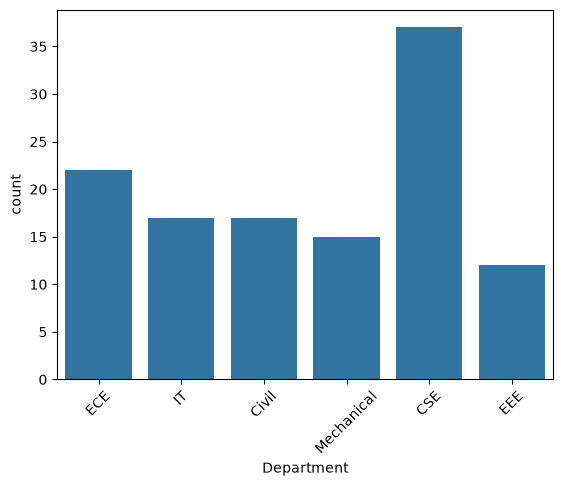

In [5]:
sns.countplot(data=df, x="Department")
plt.xticks(rotation=45)
plt.show()

In [6]:
df["Gender"].value_counts()

Gender
Male      63
Female    57
Name: count, dtype: int64

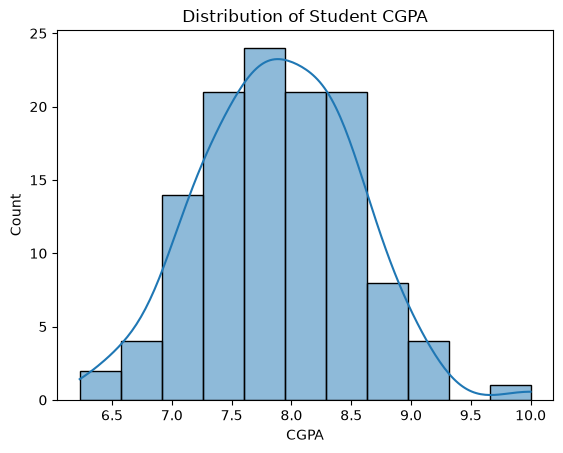

In [7]:
sns.histplot(df["CGPA"], kde=True)
plt.title("Distribution of Student CGPA")
plt.show()

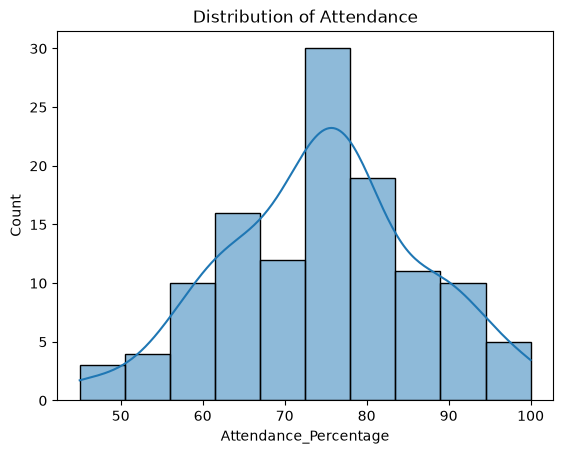

In [8]:
sns.histplot(df["Attendance_Percentage"], kde=True)
plt.title("Distribution of Attendance")
plt.show()

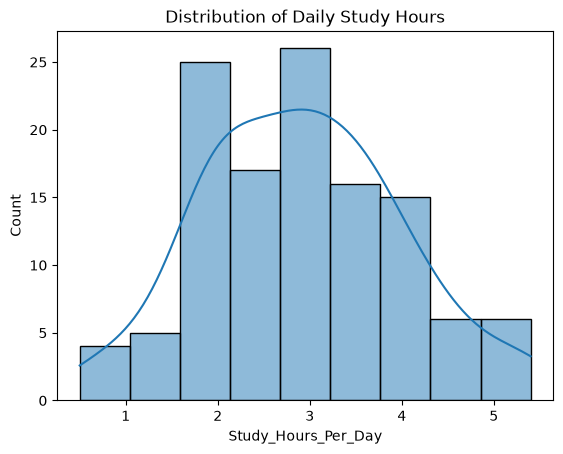

In [9]:
sns.histplot(df["Study_Hours_Per_Day"], kde=True)
plt.title("Distribution of Daily Study Hours")
plt.show()

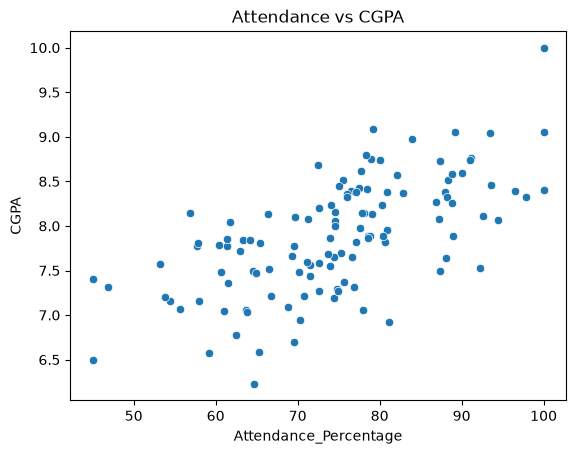

In [ ]:
# Does attendance relate to CGPA?
sns.scatterplot(
    data=df,
    x="Attendance_Percentage",
    y="CGPA"
)

plt.title("Attendance vs CGPA")
plt.show()

In [11]:
df["Attendance_Percentage"].corr(df["CGPA"])

np.float64(0.637886211972635)

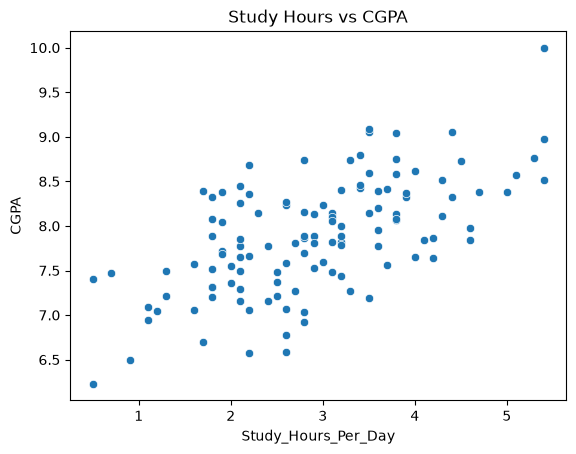

In [ ]:
# Study hours vs CGPA
sns.scatterplot(
    data=df,
    x="Study_Hours_Per_Day",
    y="CGPA"
)

plt.title("Study Hours vs CGPA")
plt.show()

In [13]:
df["Study_Hours_Per_Day"].corr(df["CGPA"])

np.float64(0.6194960730945323)

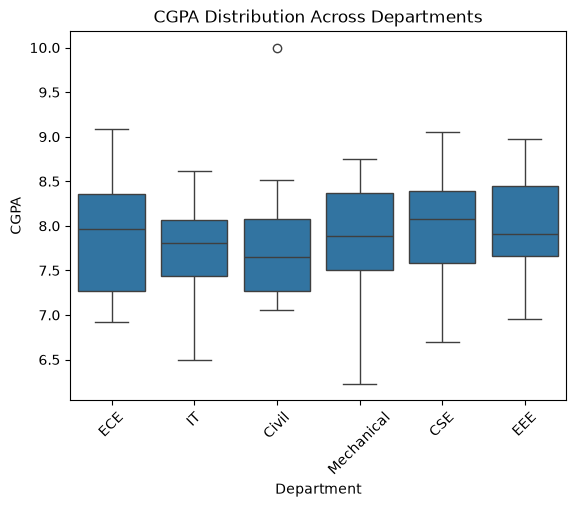

In [ ]:
# Department vs CGPA
sns.boxplot(
    data=df,
    x="Department",
    y="CGPA"
)

plt.xticks(rotation=45)
plt.title("CGPA Distribution Across Departments")
plt.show()

In [ ]:
# AI usage analysis
df["AI_Usage_Frequency"].value_counts()

AI_Usage_Frequency
Sometimes     32
Often         32
Rarely        28
Very often    16
Never         12
Name: count, dtype: int64

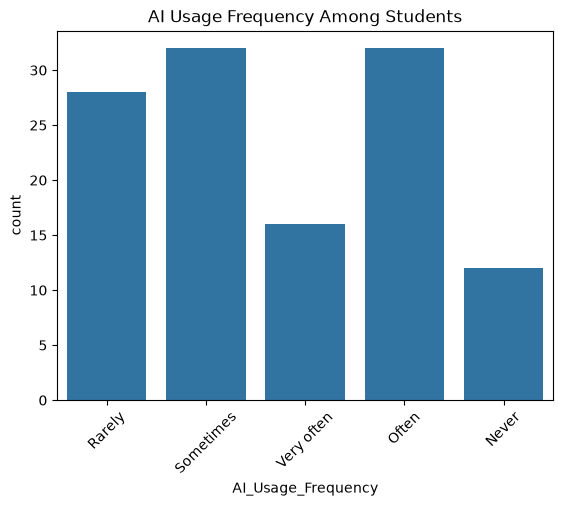

In [16]:
sns.countplot(
    data=df,
    x="AI_Usage_Frequency"
)

plt.xticks(rotation=45)
plt.title("AI Usage Frequency Among Students")
plt.show()

In [17]:
# AI usage vs learning improvement
pd.crosstab(
    df["AI_Usage_Frequency"],
    df["AI_Improves_Learning"],
    normalize="index"
) * 100

AI_Improves_Learning,Agree,Disagree,Neutral,Strongly agree,Strongly disagree
AI_Usage_Frequency,,,,,
Never,58.333333,0.000000,8.333333,25.000000,8.333333
Often,59.375000,0.000000,28.125000,12.500000,0.000000
Rarely,57.142857,7.142857,21.428571,10.714286,3.571429
Sometimes,43.750000,18.750000,15.625000,15.625000,6.250000
Very often,56.250000,6.250000,12.500000,18.750000,6.250000


In [18]:
# Satisfaction analysis

satisfaction_columns = [
    "Teaching_Quality",
    "Course_Content",
    "Faculty_Support",
    "Learning_Resources",
    "Infrastructure",
    "Placement_Support"
]

df[satisfaction_columns].mean().sort_values(ascending=False)

Faculty_Support       3.650000
Teaching_Quality      3.575000
Course_Content        3.350000
Infrastructure        3.250000
Learning_Resources    3.216667
Placement_Support     3.108333
dtype: float64

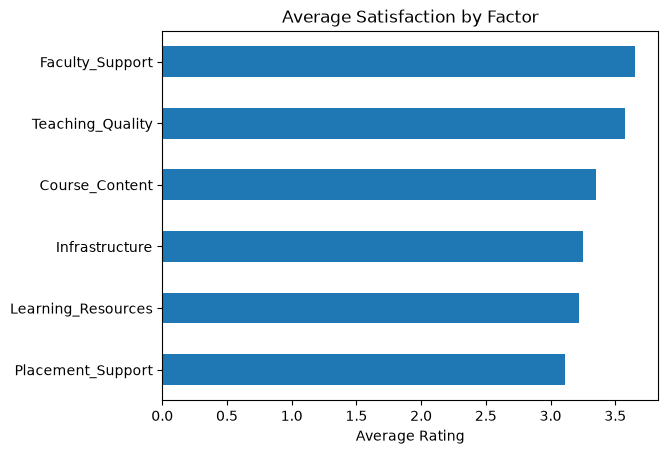

In [19]:
df[satisfaction_columns].mean().sort_values().plot(kind="barh")

plt.title("Average Satisfaction by Factor")
plt.xlabel("Average Rating")
plt.show()

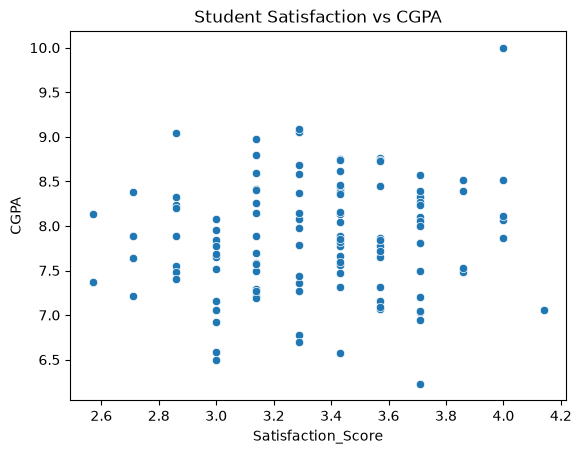

In [20]:
# Satisfaction vs CGPA
sns.scatterplot(
    data=df,
    x="Satisfaction_Score",
    y="CGPA"
)

plt.title("Student Satisfaction vs CGPA")
plt.show()


In [21]:
df["Satisfaction_Score"].corr(df["CGPA"])

np.float64(0.10399868171234974)

In [22]:
# Multivariate analysis
numeric_columns = [
    "Age",
    "Study_Hours_Per_Day",
    "Attendance_Percentage",
    "CGPA",
    "Teaching_Quality",
    "Course_Content",
    "Faculty_Support",
    "Learning_Resources",
    "Infrastructure",
    "Placement_Support",
    "Overall_Satisfaction",
    "Satisfaction_Score"
]

corr = df[numeric_columns].corr()

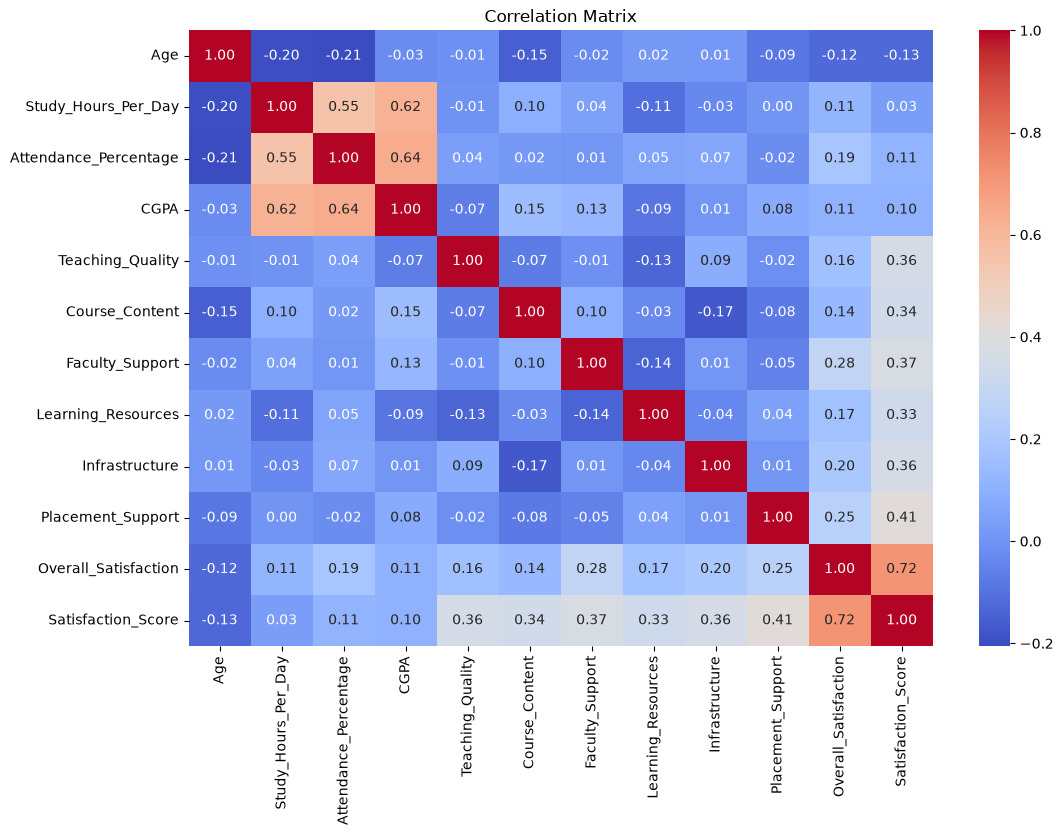

In [23]:
plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()